# Bassez et al. 2021 — Breast Cancer (10x)
## 03 · Signatures — module geography & Gate 2

Score Gast/pSom/Crest on the malignant manifold and read the geography. **Gate 2**: is the embryonic module pattern present? Here Gast/pSom weakly co-repress near the origin and Crest is an inverse terminal gradient -> the **non-branching** case: GO, with no bifurcation (Gate 3 = NA). Deliverable panels show **raw** per-cell scores.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 65464 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 78/81 genes present
pSom: 93/98 genes present
Crest: 104/104 genes present


### Module geography and the Gate-2 call
Gast/pSom co-vary weakly and both oppose Crest; pseudotime rises pSom/Gast (root) -> Crest (terminus). A **joint pSom&Crest-high enrichment < 1** means Crest is an inverse terminal gradient, not a co-expressed hub -> single axis, non-branching. Also test whether Crest enriches the **Gast** pole (the inversion flag).

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
print('raw module means (global strength):', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
def _enr(A_,B_):
    az=(adata.obs[A_]-adata.obs[A_].mean())/adata.obs[A_].std()
    bz=(adata.obs[B_]-adata.obs[B_].mean())/adata.obs[B_].std()
    joint=((az>0.5)&(bz>0.5)).mean(); exp=(az>0.5).mean()*(bz>0.5).mean()
    return joint/exp
print(f'joint pSom&Crest-high enrichment = {_enr("pSom","Crest"):.2f} (<1 = inverse terminal gradient)')
print(f'joint Gast&Crest-high enrichment = {_enr("Gast","Crest"):.2f} (>1 would flag Crest co-enriching the Gast pole)')
print(f'joint Gast&pSom-high enrichment  = {_enr("Gast","pSom"):.2f}')
enr_pc = _enr("pSom","Crest"); enr_gc = _enr("Gast","Crest")
r_cp = np.corrcoef(adata.obs['Crest_sm'], adata.obs['pSom_sm'])[0,1]
r_cg = np.corrcoef(adata.obs['Crest_sm'], adata.obs['Gast_sm'])[0,1]
inverse_terminal = (enr_pc < 1) and (r_cp < -0.3)          # Crest is an inverse terminal gradient vs pSom
module_present   = adata.obs[['Gast','pSom','Crest']].abs().mean().max() > 0   # modules score on the manifold
gate2_go = inverse_terminal and module_present
crest_arm_flag = (enr_gc > 1) or (r_cg > 0.3)              # Crest co-enriches the Gast pole = inversion
assert gate2_go, f'Gate 2 not met: inverse_terminal={inverse_terminal} (enr_pc={enr_pc:.2f}, r_cp={r_cp:+.2f})'
print(f'Gate 2: single (Gast/pSom origin)->Crest terminal gradient (enr pSom&Crest={enr_pc:.2f}<1, Crest~pSom={r_cp:+.2f}), '
      f'weak Gast/pSom co-repression, no diverging Gast arm -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA')
print(f'Crest-arm inversion flag = {crest_arm_flag} (Gast&Crest enr={enr_gc:.2f}, Crest~Gast={r_cg:+.2f}; '
      f'Crest {"co-enriches Gast pole" if crest_arm_flag else "tracks terminus not Gast pole -> NOT flagged"})')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.20
  Crest_sm vs Gast_sm: r = -0.24
  Crest_sm vs pSom_sm: r = -0.82
raw module means (global strength): {'Gast': -0.0136, 'pSom': 0.0221, 'Crest': -0.0051}
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.099
  pSom_sm: rho = -0.282
  Crest_sm: rho = +0.284
Neural-crest-high decile mean pseudotime = 0.40 (terminal if ~1)
joint pSom&Crest-high enrichment = 0.23 (<1 = inverse terminal gradient)
joint Gast&Crest-high enrichment = 0.50 (>1 would flag Crest co-enriching the Gast pole)
joint Gast&pSom-high enrichment  = 0.93
Gate 2: single (Gast/pSom origin)->Crest terminal gradient (enr pSom&Crest=0.23<1, Crest~pSom=-0.82), weak Gast/pSom co-repression, no diverging Gast arm -> GO (non-branching)
Gate 3: no bifurcation -> NA
Crest-arm inversion flag = False (Gast&Crest enr=0.50, Crest~Gast=-0.24; Crest tracks terminus not Gast pole -> NOT flagged)


### Signature UMAPs — raw per-cell scores (deliverable)
House style (3.5,1.5), plasma, house orientation; external colorbars. **Raw** scores shown (smoothing aided the analysis above but the panels show the honest per-cell readout).

<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<cell5>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


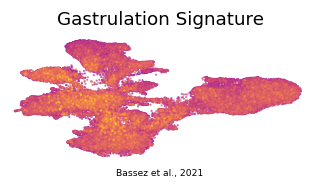

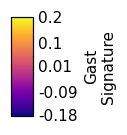

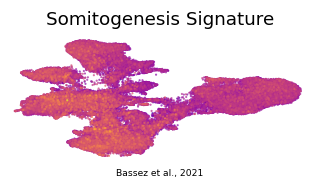

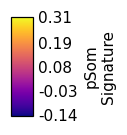

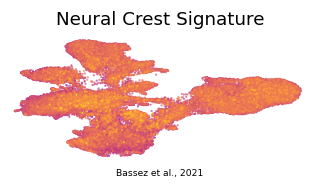

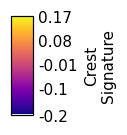

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=8, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Bassez et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
    plt.show()

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (65464, 22208)
